In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [4]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [9]:
# Dataset paths
base_dir = r"data/Skin Lesions Classification"  # Update if necessary
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

In [10]:
# Image parameters
img_size = 224
batch_size = 32
num_classes = 2
num_epochs = 100
patience = 10

In [11]:
# Data augmentation and normalization
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(img_size),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])


In [12]:
# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_size = int(0.2 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_data, val_data = torch.utils.data.random_split(train_dataset, [train_size, val_size])

test_data = datasets.ImageFolder(test_dir, transform=val_test_transforms)

In [13]:
# Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

In [14]:
# Define CNN model
class SkinLesionCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(SkinLesionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SkinLesionCNN(num_classes=num_classes).to(device)

In [15]:
# Loss & optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [59]:
# Training loop with early stopping
best_val_acc = 0
counter = 0
train_acc_hist, val_acc_hist = [], []
train_loss_hist, val_loss_hist = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, train_correct = 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels.data)

    train_loss /= len(train_loader.dataset)
    train_acc = train_correct.double() / len(train_loader.dataset)

    model.eval()
    val_loss, val_correct = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * imgs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels.data)

    val_loss /= len(val_loader.dataset)
    val_acc = val_correct.double() / len(val_loader.dataset)

    train_acc_hist.append(train_acc.item())
    val_acc_hist.append(val_acc.item())
    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}, "
          f"Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'skin_lesions_model.pth')
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping.")
            break

# Load best model
model.load_state_dict(torch.load('skin_lesions_model.pth'))

Epoch 1/100, Train Acc: 0.7118, Val Acc: 0.7742
Epoch 2/100, Train Acc: 0.7900, Val Acc: 0.7875
Epoch 3/100, Train Acc: 0.7877, Val Acc: 0.7856
Epoch 4/100, Train Acc: 0.7981, Val Acc: 0.7628
Epoch 5/100, Train Acc: 0.8057, Val Acc: 0.8121
Epoch 6/100, Train Acc: 0.8104, Val Acc: 0.7989
Epoch 7/100, Train Acc: 0.8114, Val Acc: 0.8121
Epoch 8/100, Train Acc: 0.8024, Val Acc: 0.7837
Epoch 9/100, Train Acc: 0.8076, Val Acc: 0.7894
Epoch 10/100, Train Acc: 0.8109, Val Acc: 0.7989
Epoch 11/100, Train Acc: 0.8043, Val Acc: 0.7932
Epoch 12/100, Train Acc: 0.8142, Val Acc: 0.8046
Epoch 13/100, Train Acc: 0.8057, Val Acc: 0.8235
Epoch 14/100, Train Acc: 0.8209, Val Acc: 0.8046
Epoch 15/100, Train Acc: 0.8180, Val Acc: 0.7989
Epoch 16/100, Train Acc: 0.8175, Val Acc: 0.8140
Epoch 17/100, Train Acc: 0.8142, Val Acc: 0.8065
Epoch 18/100, Train Acc: 0.8142, Val Acc: 0.8083
Epoch 19/100, Train Acc: 0.8346, Val Acc: 0.8008
Epoch 20/100, Train Acc: 0.8194, Val Acc: 0.8065
Epoch 21/100, Train Acc: 0.82

C:\Users\rupes\AppData\Local\Temp\ipykernel_8012\2317298171.py:58: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('skin_lesions_model.pth'))


<All keys matched successfully>

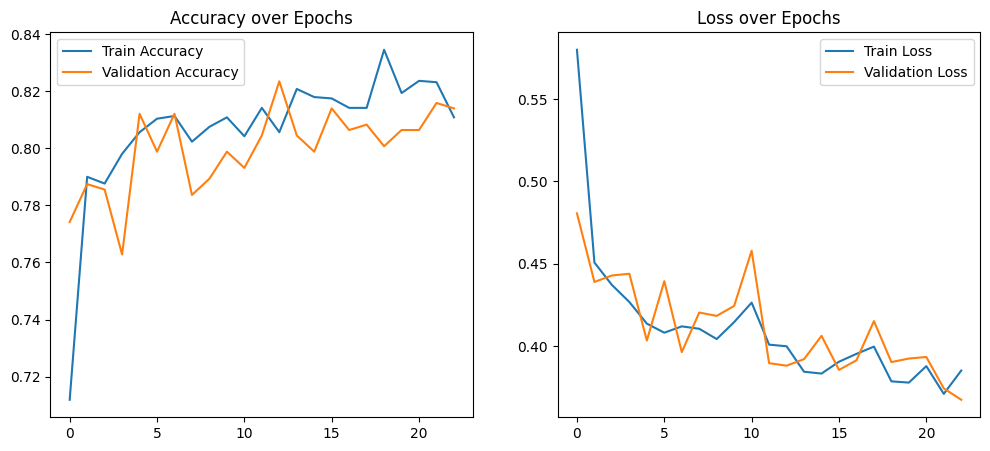

In [61]:
# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_acc_hist, label='Train Accuracy')
plt.plot(val_acc_hist, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_loss_hist, label='Train Loss')
plt.plot(val_loss_hist, label='Validation Loss')
plt.title('Loss over Epochs')
plt.legend()
plt.show()


In [64]:
# Recreate model structure before loading weights
model = SkinLesionCNN(num_classes=2)
model.load_state_dict(torch.load('skin_lesions_model.pth'))
model.to(device)
model.eval()

C:\Users\rupes\AppData\Local\Temp\ipykernel_8012\1842441496.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('skin_lesions_model.pth'))


SkinLesionCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=50176, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=2, bias=True)
  

In [65]:
from PIL import Image
from torchvision import transforms
import torch.nn.functional as F

# Transform used during testing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# Class labels (must match training order)
class_names = ['benign', 'malignant']

def predict_image(image_path, model):
    image = Image.open(image_path).convert('RGB')
    img_tensor = transform(image).unsqueeze(0).to(device)  # Add batch dimension
    
    with torch.no_grad():
        output = model(img_tensor)
        probs = F.softmax(output, dim=1)
        confidence, pred_idx = torch.max(probs, 1)
    
    predicted_label = class_names[pred_idx.item()]
    return predicted_label, confidence.item()

In [66]:
image_path = r"Skin Lesions Classification\test\malignant\3.jpg"
label, confidence = predict_image(image_path, model)
print(f"Prediction: {label} ({confidence*100:.2f}% confidence)")

Prediction: malignant (92.66% confidence)


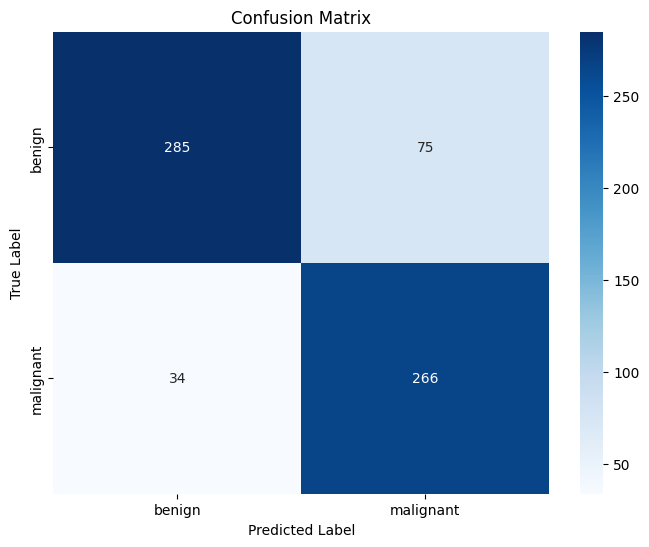

In [67]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect predictions and true labels
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [68]:
print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))


Classification Report:

              precision    recall  f1-score   support

      benign       0.89      0.79      0.84       360
   malignant       0.78      0.89      0.83       300

    accuracy                           0.83       660
   macro avg       0.84      0.84      0.83       660
weighted avg       0.84      0.83      0.84       660



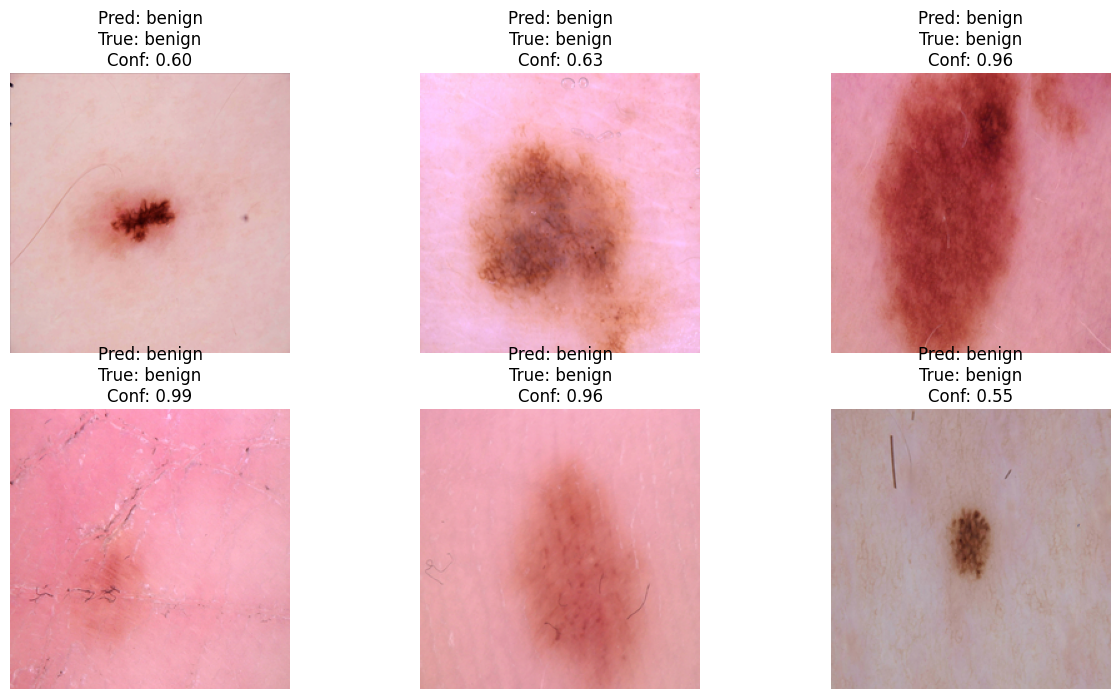

In [69]:
def visualize_predictions(model, data_loader, num_images=6):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 8))
    
    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(probs, 1)
            
            for i in range(imgs.size(0)):
                if images_shown == num_images:
                    return
                image = imgs[i].cpu().permute(1, 2, 0).numpy()
                image = (image * 0.5) + 0.5  # Unnormalize
                plt.subplot(2, 3, images_shown+1)
                plt.imshow(image)
                plt.axis('off')
                plt.title(f"Pred: {class_names[preds[i]]}\nTrue: {class_names[labels[i]]}\nConf: {probs[i][preds[i]]:.2f}")
                images_shown += 1

visualize_predictions(model, test_loader)


In [70]:
print(f"\n✅ Final Test Accuracy: {test_acc.item()*100:.2f}%")



✅ Final Test Accuracy: 83.48%


ROC-AUC: 0.4875
PR-AUC: 0.4981


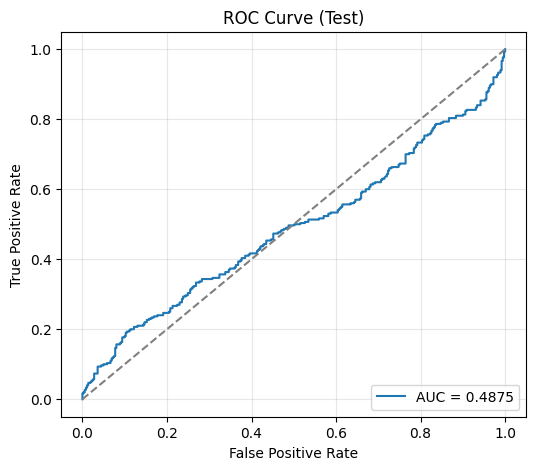

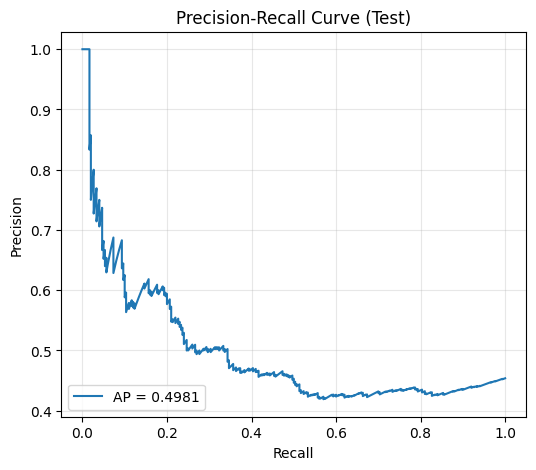

In [16]:
# --- ROC/PR AUC evaluation cell (auto-added) ---
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

missing = [name for name in ["model", "test_loader"] if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing required objects: " + ", ".join(missing) +
        ". Run the notebook setup/training/loading cells first, then run this AUC cell."
    )

model.eval()
y_true, y_prob_pos = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        logits = model(imgs)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.cpu().numpy().tolist())
        y_prob_pos.extend(probs[:, 1].cpu().numpy().tolist())

y_true = np.array(y_true)
y_prob_pos = np.array(y_prob_pos)

roc_auc = roc_auc_score(y_true, y_prob_pos)
pr_auc = average_precision_score(y_true, y_prob_pos)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")

fpr, tpr, _ = roc_curve(y_true, y_prob_pos)
roc_curve_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_curve_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

precision, recall, _ = precision_recall_curve(y_true, y_prob_pos)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AP = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Test)")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()
